## Water Levels at Banagher Bridge, River Shannon

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import xgboost as xgb
from datetime import datetime
from sklearn.metrics import mean_squared_error

colour_pal = sns.color_palette()
#plt.style.use('fivethirtyeight') # - I am not sure I like this

# https://waterlevel.ie/hydro-data/#/overview/Waterlevel/station/11617/Banagher/Qdownload
## correct for height above malin head
height = 30.330 # this is height of sensor 25017 above Malin Head
#df['DayMin'] = df['DayMin'] - height
'''
I want to calculate the floodline here, 
## Suggest last thursday is 3 feet above flood. - Dec 2023, check data for exact date!
Find scalar for flood level in M. 
also import mean and percentile values from the waterlevels website, and compare them.
'''

#importing the datasets
# this dataset has the hourly readouts.
df = pd.read_csv('tsvalues.csv', sep=';', skiprows=10).iloc[:, :-1] # drop the water quality for now
df['Timestamp'] = df['#Timestamp']

df = df.set_index('Timestamp') # set the index

#issue is data is set = "%d/%m/%Y" - this should make this ok.
df.index = pd.to_datetime(df.index, format='mixed', dayfirst=True)
df['Value'] = df['Value'] - height # to recalibrate water level, keep colname value for now.

# this dataset has one datapoint for each day. # dataset 2
df2 = pd.read_csv('25017_banagher_s_complete.csv', skiprows=12).iloc[:, :-1] # for now exclude the quality column

df2 = df2.set_index('Day') # set the index

#issue is data is set = "%d/%m/%Y" - this should make this ok.
df2.index = pd.to_datetime(df2.index, format='mixed', dayfirst=True)

# to recalibrate water levels
df2['Day Min'] = df2['Day Min'] - height 
df2['Day Mean'] = df2['Day Mean'] - height 
df2['Day Max'] = df2['Day Max'] - height 

# some more work may be needed here

In [2]:
df2.head()
#df.tail()
#df.index

,Day Min,Day Mean,Day Max
Day,,,
1989-01-02,2.905,2.95,2.982
1989-01-03,2.774,2.84,2.905
1989-01-04,2.757,2.76,2.774
1989-01-05,2.764,2.81,2.874
1989-01-06,2.874,2.97,3.037


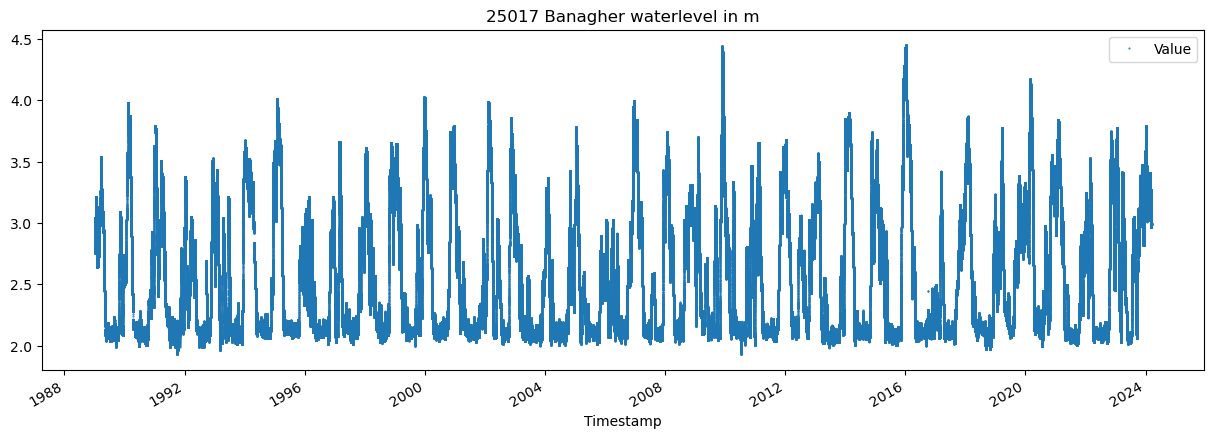

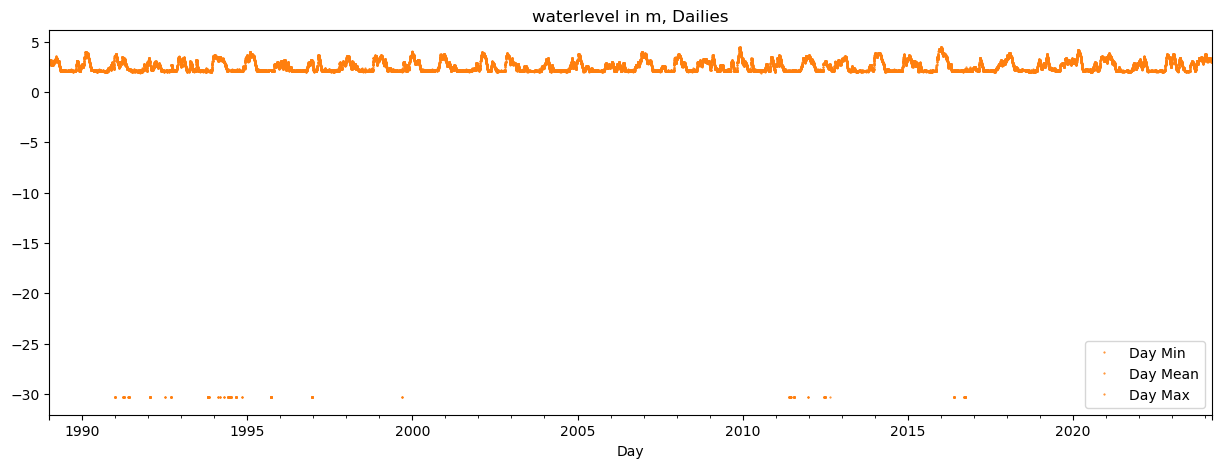

In [3]:
df.plot(style='.', 
        figsize=(15,5), 
        color=colour_pal[0], 
        title='25017 Banagher waterlevel in m',
        markersize=1)
plt.show()

df2.plot(style='.', 
        figsize=(15,5), 
        color=colour_pal[1], 
        title='waterlevel in m, Dailies',
        markersize=1)
plt.show()

# issues here with zeros on the second plot but I will come to fix this.


In [4]:
#df.index

## Train / Test Split

In [5]:
# later I will change this to full cross validation

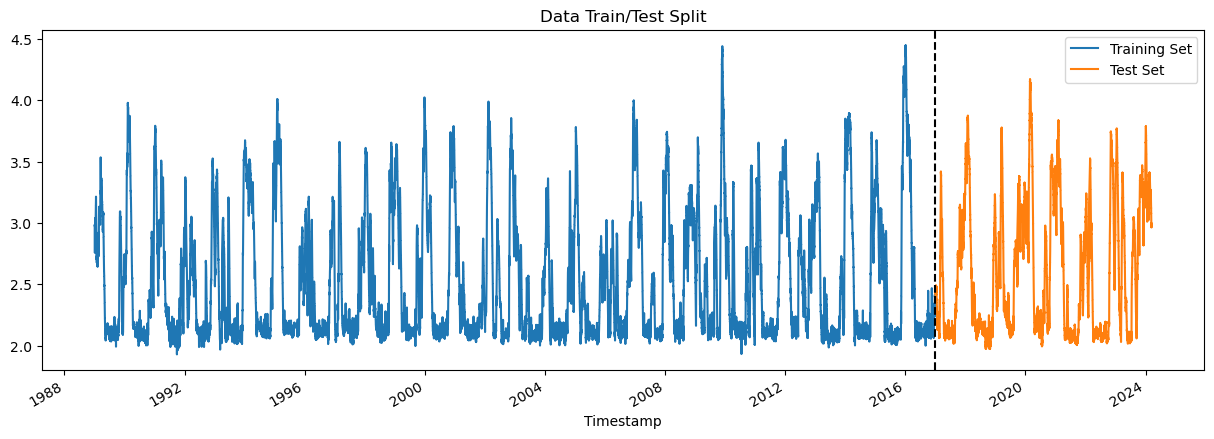

In [6]:
train = df.loc[df.index < '01-01-2017']
test = df.loc[df.index >= '01-01-2017']

fig, ax = plt.subplots(figsize=(15, 5))
train.plot(ax=ax, label='Training Set', title='Data Train/Test Split')
test.plot(ax=ax, label='Test Set')

ax.axvline('01-01-2017', color='black', ls='--')
ax.legend(['Training Set', 'Test Set'])
plt.show()


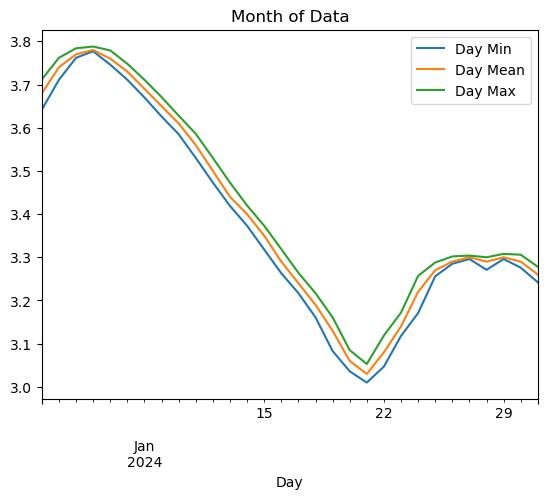

In [7]:
# weekly plot, or monthly
df2.loc[(df2.index > '01-01-2024') & (df2.index <= '31-01-2024')].plot(title='Month of Data') 
plt.show()

# the weekly seems trivial, but the monthly is relevant with the daily data.
# maybe I will revisit this and put in a number of months where we want some detail.
# quarterly here might actually be better, for the months where there is risk of flood water.

### Feature Creation

In [8]:
df.index

DatetimeIndex(['1989-01-02 09:00:00+00:00', '1989-01-02 09:15:00+00:00',
               '1989-01-02 09:30:00+00:00', '1989-01-02 09:45:00+00:00',
               '1989-01-02 10:00:00+00:00', '1989-01-02 10:15:00+00:00',
               '1989-01-02 10:30:00+00:00', '1989-01-02 10:45:00+00:00',
               '1989-01-02 11:00:00+00:00', '1989-01-02 11:15:00+00:00',
               ...
               '2024-03-13 22:15:00+00:00', '2024-03-13 22:30:00+00:00',
               '2024-03-13 22:45:00+00:00', '2024-03-13 23:00:00+00:00',
               '2024-03-13 23:15:00+00:00', '2024-03-13 23:30:00+00:00',
               '2024-03-13 23:45:00+00:00', '2024-03-14 00:00:00+00:00',
               '2024-03-14 00:15:00+00:00', '2024-03-14 00:30:00+00:00'],
              dtype='datetime64[ns, UTC]', name='Timestamp', length=1218710, freq=None)

In [9]:
df2.index

DatetimeIndex(['1989-01-02', '1989-01-03', '1989-01-04', '1989-01-05',
               '1989-01-06', '1989-01-07', '1989-01-08', '1989-01-09',
               '1989-01-10', '1989-01-11',
               ...
               '2024-03-04', '2024-03-05', '2024-03-06', '2024-03-07',
               '2024-03-08', '2024-03-09', '2024-03-10', '2024-03-11',
               '2024-03-12', '2024-03-13'],
              dtype='datetime64[ns]', name='Day', length=12855, freq=None)

In [16]:
def create_features(df):
    '''
    Create time series features based on time series index.
    '''
    df = df.copy()
    df['hour'] = df.index.hour # trivial for waterlevels
    df['dayofweek'] = df.index.day_of_week # trivial for waterlevels
    df['quarter'] = df.index.quarter # not interesting for waterlevels
    df['month'] = df.index.month
    df['year'] = df.index.year
    df['dayofyear'] = df.index.day_of_year
    return df

df = create_features(df)

def create_features_simple(df):
    '''
    Create time series features based on time series index.
    The function that looks at the average daily values can be used for year on year comparison
    '''    
    df['dayofweek'] = df.index.day_of_week # trivial for waterlevels
    df['quarter'] = df.index.quarter # not interesting for waterlevels
    df['month'] = df.index.month
    df['year'] = df.index.year
    df['dayofyear'] = df.index.day_of_year
    return df

df2 = create_features_simple(df2)

In [17]:
df.tail(25)

,#Timestamp,Value,hour,dayofweek,quarter,month,year,dayofyear
Timestamp,,,,,,,,
2024-03-13 18:30:00+00:00,2024-03-13T18:30:00.000Z,2.985,18,2,1,3,2024,73
2024-03-13 18:45:00+00:00,2024-03-13T18:45:00.000Z,2.986,18,2,1,3,2024,73
2024-03-13 19:00:00+00:00,2024-03-13T19:00:00.000Z,2.985,19,2,1,3,2024,73
2024-03-13 19:15:00+00:00,2024-03-13T19:15:00.000Z,2.985,19,2,1,3,2024,73
2024-03-13 19:30:00+00:00,2024-03-13T19:30:00.000Z,2.986,19,2,1,3,2024,73
2024-03-13 19:45:00+00:00,2024-03-13T19:45:00.000Z,2.987,19,2,1,3,2024,73
2024-03-13 20:00:00+00:00,2024-03-13T20:00:00.000Z,2.985,20,2,1,3,2024,73
2024-03-13 20:15:00+00:00,2024-03-13T20:15:00.000Z,2.986,20,2,1,3,2024,73
2024-03-13 20:30:00+00:00,2024-03-13T20:30:00.000Z,2.987,20,2,1,3,2024,73


In [12]:
df2.tail(25)

,Day Min,Day Mean,Day Max,dayofweek,quarter,month,year,dayofyear
Day,,,,,,,,
2024-02-18,3.402,3.41,3.410,6,1,2,2024,49
2024-02-19,3.389,3.40,3.406,0,1,2,2024,50
2024-02-20,3.366,3.38,3.390,1,1,2,2024,51
2024-02-21,3.348,3.35,3.367,2,1,2,2024,52
2024-02-22,3.350,3.35,3.357,3,1,2,2024,53
2024-02-23,3.339,3.35,3.354,4,1,2,2024,54
2024-02-24,3.318,3.33,3.341,5,1,2,2024,55
2024-02-25,3.293,3.31,3.320,6,1,2,2024,56
2024-02-26,3.244,3.27,3.294,0,1,2,2024,57


### Visualise our feature / target relationship

Text(0.5, 1.0, 'Waterlevel in M')

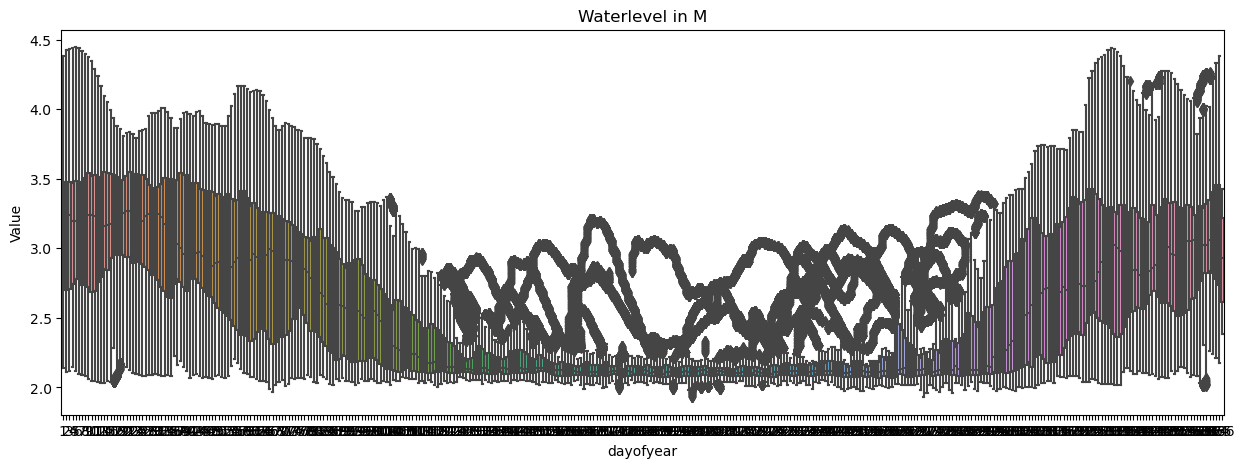

In [13]:
fig, ax = plt.subplots(figsize=(15,5))
sns.boxplot(data=df, x='dayofyear', y='Value')
ax.set_title('Waterlevel in M')
# this example here is too detailed, maybe I need to calculate a weekly average from the average of the daily averages.
# another trivial example here if I explore the other dataset.

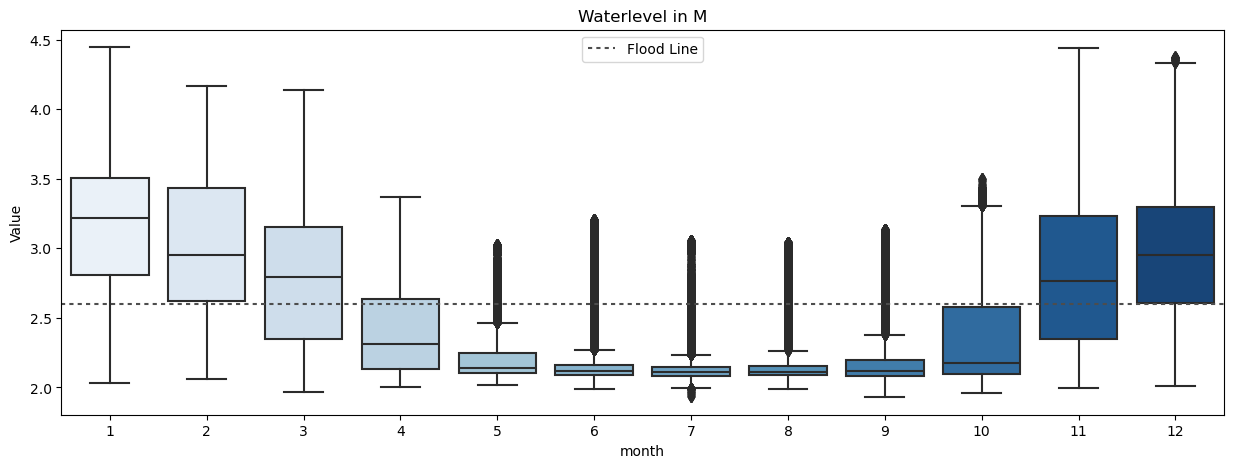

In [14]:
fig, ax = plt.subplots(figsize=(15,5))
sns.boxplot(data=df, x='month', y='Value', palette='Blues')
ax.set_title('Waterlevel in M')
# I should put in the floodline here, for average projection of flooding in the future
# this is an absolute guess for first order approximation.
ax.axhline(2.6, color=".3", dashes=(2, 2), label='Flood Line')
plt.legend()
plt.show()

In [15]:
# more scope for plots here, insert lines for percentiles, day of the year trends, quarterly and monthly year on year comparison
# looking for waterlevels websites definition for what is in flood and our estimation for flood levels in the field.

### Our Model
##### Regression model

In [27]:
train = create_features(train)
test = create_features(test)

FEATURES = ['hour', 'dayofweek', 'quarter', 'month', 'year', 'dayofyear']
TARGET = ['Value']

X_train = train[FEATURES]
y_train = train[TARGET]

X_test = test[FEATURES]
y_test = test[TARGET]

In [28]:
reg = xgb.XGBRegressor(n_estimators=1000, early_stopping_rounds=50) # is this accurate enough in this case?
reg.fit(X_train, y_train,
        eval_set=[(X_train, y_train), (X_test, y_test)],
        verbose=True)

[0]	validation_0-rmse:1.47761	validation_1-rmse:1.55768
[1]	validation_0-rmse:1.05507	validation_1-rmse:1.16085
[2]	validation_0-rmse:0.76418	validation_1-rmse:0.91170
[3]	validation_0-rmse:0.56675	validation_1-rmse:0.76596
[4]	validation_0-rmse:0.43607	validation_1-rmse:0.67390
[5]	validation_0-rmse:0.35193	validation_1-rmse:0.64357
[6]	validation_0-rmse:0.29632	validation_1-rmse:0.62418
[7]	validation_0-rmse:0.26127	validation_1-rmse:0.60922
[8]	validation_0-rmse:0.24022	validation_1-rmse:0.61302
[9]	validation_0-rmse:0.22286	validation_1-rmse:0.61130
[10]	validation_0-rmse:0.21143	validation_1-rmse:0.61553
[11]	validation_0-rmse:0.20298	validation_1-rmse:0.61509
[12]	validation_0-rmse:0.19159	validation_1-rmse:0.61689
[13]	validation_0-rmse:0.18779	validation_1-rmse:0.62154
[14]	validation_0-rmse:0.18053	validation_1-rmse:0.62195
[15]	validation_0-rmse:0.17425	validation_1-rmse:0.62116
[16]	validation_0-rmse:0.17295	validation_1-rmse:0.62159
[17]	validation_0-rmse:0.16882	validation

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, early_stopping_rounds=50,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, gpu_id=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=None, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=None, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             n_estimators=1000, n_jobs=None, num_parallel_tree=None,
             predictor=None, random_state=None, ...)

I suspect there is overfitting here, so I will try again.

In [34]:
reg = xgb.XGBRegressor(n_estimators=3000, 
                       early_stopping_rounds=50,
                       learning_rate=0.005) # Regularization
reg.fit(X_train, y_train,
        eval_set=[(X_train, y_train), (X_test, y_test)],
        verbose=100)

[0]	validation_0-rmse:2.07732	validation_1-rmse:2.17135
[100]	validation_0-rmse:1.28012	validation_1-rmse:1.37040
[200]	validation_0-rmse:0.80498	validation_1-rmse:0.93854
[300]	validation_0-rmse:0.52674	validation_1-rmse:0.72806
[400]	validation_0-rmse:0.37168	validation_1-rmse:0.64330
[500]	validation_0-rmse:0.28924	validation_1-rmse:0.61498
[600]	validation_0-rmse:0.24587	validation_1-rmse:0.60951
[654]	validation_0-rmse:0.22995	validation_1-rmse:0.60944


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, early_stopping_rounds=50,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, gpu_id=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.005, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=None, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             n_estimators=3000, n_jobs=None, num_parallel_tree=None,
             predictor=None, random_state=None, ...)

In [33]:
### Feature Importances

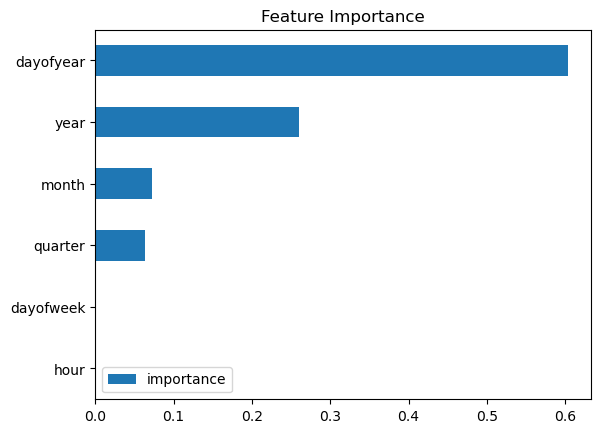

In [39]:
fi = pd.DataFrame(data=reg.feature_importances_,
                  index=reg.feature_names_in_,
                  columns=['importance'])

fi.sort_values('importance').plot(kind='barh', title='Feature Importance')
plt.show()    

This is showing that breaking down the first dataset into hour or day of the week is trivial. Using the day of the year, and similarly its quater and months can be handy. The year is also important, and I will investigate by looking at the flood windows by year on year.